# Shared setup and data loading

This notebook uses the **incident-level cleaned dataset**. Each row should represent one unique `Incident ID`, not one offence record. Multi-valued offence fields are stored as strings separated by ` | `.

The analysis is descriptive and exploratory, in line with the CI7340 brief. The coursework requires 10 research questions and 20 question-linked visualisations overall; this notebook contributes two visualisations to its assigned research question.

**Input:** `crime_dataset_incident_level_cleaned.csv`

> Run the notebook from top to bottom. Keep the original cleaned dataset unchanged.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter
from scipy.stats import chi2_contingency, spearmanr, kruskal
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 120

In [2]:
df = pd.read_csv("crime_dataset_incident_level_cleaned.csv", low_memory=False)

In [3]:
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print(f"Unique Incident IDs: {df['Incident ID'].nunique():,}")
print(f"Duplicate Incident IDs: {df['Incident ID'].duplicated().sum():,}")

Rows: 467,601
Columns: 50
Unique Incident IDs: 467,601
Duplicate Incident IDs: 0


## Data integrity check

The incident-level unit of analysis is essential here. The following check confirms that each `Incident ID` appears once. If duplicate IDs are found, stop and resolve the issue rather than silently dropping rows.

In [4]:
assert df["Incident ID"].is_unique, (
    "Incident ID is not unique. This file is not one-row-per-incident."
)

## Parse multi-valued fields

During incident-level aggregation, offence labels were retained as pipe-separated unique values. This helper converts those strings into lists and removes empty or duplicate labels. It supports both single-offence and multi-offence incidents.

In [5]:
def split_multi_value(value):
    if pd.isna(value):
        return []
    return list(dict.fromkeys(
        item.strip() for item in str(value).split("|") if item.strip()
    ))

# H1 — Offence-category co-occurrence within incidents

## Research question

**Are certain offence categories more likely to occur together within the same crime incident?**

### Analytical framing
- **Unit of analysis:** one unique `Incident ID`.
- **Explanatory information (X):** the set of NIBRS offence categories (`Crime Name2`) recorded within an incident.
- **Outcome (Y):** the frequency and strength of co-occurrence between pairs of offence categories.
- **Expected evidence:** repeated category pairs and pairwise association strength.

The incident-level file stores multiple `Crime Name2` values in a single field for incidents with more than one offence. We therefore split the field into unique labels before generating pairs. Each incident contributes at most once to a given pair.

## 1. Prepare offence-category sets

The analysis uses `Crime Name2`, the NIBRS offence-name level. This is more informative for co-occurrence than the four broad `Crime Name1` groups. The generic `All Other Offenses` category is retained in the main analysis because it is part of the supplied reporting data, but its catch-all nature must be considered when interpreting pairs.

In [6]:
required = ["Incident ID", "Crime Name2", "Total_Offence_Records"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

In [7]:
df["offence_categories"] = df["Crime Name2"].apply(split_multi_value)

In [8]:
df["category_count"] = df["offence_categories"].apply(len)

In [9]:
category_incident_counts = (
    df[["Incident ID", "offence_categories"]]
    .explode("offence_categories")
    .dropna(subset=["offence_categories"])
    .drop_duplicates(["Incident ID", "offence_categories"])
    ["offence_categories"]
    .value_counts()
)
display(category_incident_counts.head(20).rename_axis("NIBRS offence category").to_frame("Incident count"))

,Incident count
NIBRS offence category,
All Other Offenses,120303
Theft From Motor Vehicle,41308
Simple Assault,36954
Shoplifting,35011
Destruction/Damage/Vandalism of Property,31969
Drug/Narcotic Violations,25483
All other Larceny,22993
Driving Under the Influence,20324
Motor Vehicle Theft,17974


## 2. Generate unique co-occurring pairs

A pair is counted only when both categories occur in the same incident. The pair count is therefore an **incident count**, not an offence-row count. Incidents containing only one unique category do not create a pair.

In [10]:
pair_counter = Counter()
for categories in df["offence_categories"]:
    unique_categories = sorted(set(categories))
    if len(unique_categories) >= 2:
        pair_counter.update(combinations(unique_categories, 2))

In [11]:
pair_counts = pd.DataFrame(
    [(a, b, count) for (a, b), count in pair_counter.items()],
    columns=["Category A", "Category B", "Incident count"]
).sort_values("Incident count", ascending=False)
display(pair_counts.head(20))

,Category A,Category B,Incident count
7,Destruction/Damage/Vandalism of Property,Theft From Motor Vehicle,2665
0,All Other Offenses,Simple Assault,1734
13,Drug Equipment Violations,Drug/Narcotic Violations,1724
2,Destruction/Damage/Vandalism of Property,Simple Assault,1596
18,Credit Card/Automatic Teller Machine Fraud,Theft From Motor Vehicle,1184
8,Burglary/Breaking and Entering,Destruction/Damage/Vandalism of Property,1145
1,Disorderly Conduct,Simple Assault,1094
27,All Other Offenses,Drug/Narcotic Violations,1062
19,Motor Vehicle Theft,Theft From Motor Vehicle,1034
30,Drug/Narcotic Violations,Weapon Law Violations,901


## Descriptive statistics

These summaries show how common multi-category incidents are and how concentrated the co-occurrence structure is. They provide context for the visualisations rather than implying that a frequent pair is causally related.

In [12]:
multi_category_incidents = int((df["category_count"] > 1).sum())
summary_h1 = pd.DataFrame({
    "Measure": [
        "Unique incidents",
        "Incidents with 2+ distinct NIBRS offence categories",
        "Percentage with 2+ distinct categories",
        "Distinct categories observed",
        "Distinct co-occurring pairs"
    ],
    "Value": [
        len(df),
        multi_category_incidents,
        multi_category_incidents / len(df) * 100,
        len(category_incident_counts),
        len(pair_counts)
    ]
})
display(summary_h1)

,Measure,Value
0,Unique incidents,467601.000000
1,Incidents with 2+ distinct NIBRS offence categ...,31135.000000
2,Percentage with 2+ distinct categories,6.658455
3,Distinct categories observed,54.000000
4,Distinct co-occurring pairs,535.000000


## Visualisation 1 — Most frequent co-occurring offence-category pairs

A horizontal bar chart is appropriate because pair labels are long and there may be many possible combinations. Showing the leading pairs makes the strongest recurring combinations readable. The x-axis is the number of unique incidents containing both categories.

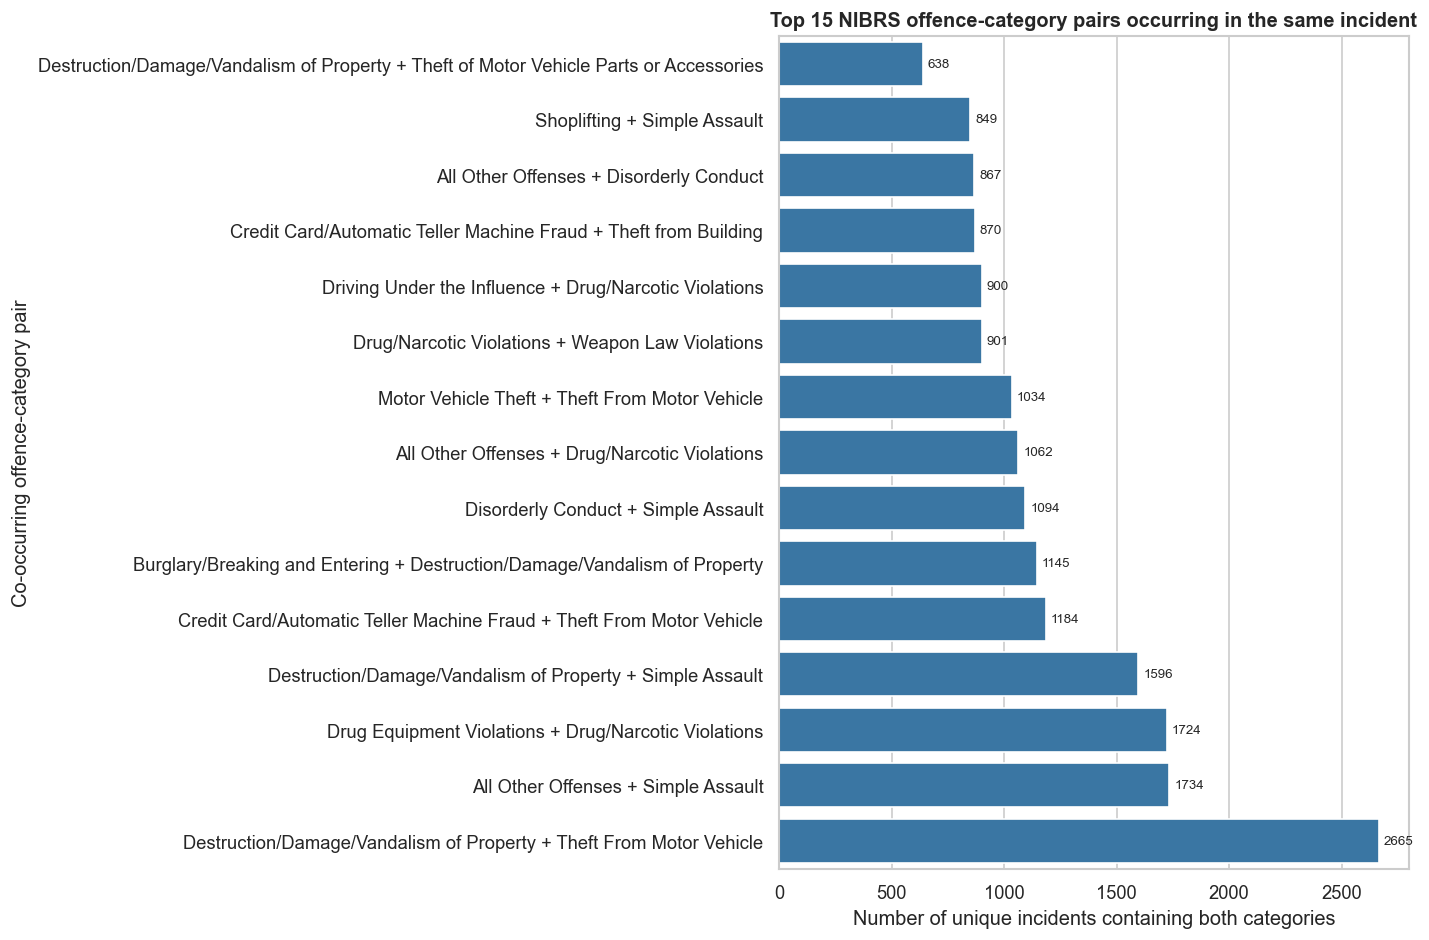

In [13]:
top_pairs = pair_counts.head(15).copy()
top_pairs["Pair"] = top_pairs["Category A"] + " + " + top_pairs["Category B"]
top_pairs = top_pairs.sort_values("Incident count")

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(data=top_pairs, x="Incident count", y="Pair", color="#2878B5", ax=ax)
ax.set_title("Top 15 NIBRS offence-category pairs occurring in the same incident", weight="bold")
ax.set_xlabel("Number of unique incidents containing both categories")
ax.set_ylabel("Co-occurring offence-category pair")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

**How to interpret Figure 1:** Focus on which pairs recur most often and whether they represent plausible operational combinations. Do not describe co-occurrence as evidence that one offence causes another. The `All Other Offenses` label is broad and may combine very different local report types, so inspect the detailed `Crime Name3` values before making substantive claims about a pair involving it.

## Visualisation 2 — Co-occurrence heatmap for the most common categories

The heatmap uses pairwise incident counts for the 12 most prevalent NIBRS offence categories. The diagonal represents the number of incidents containing each category; off-diagonal cells represent incidents containing both categories. A shared colour scale makes stronger pairings easy to identify.

In [14]:
top_categories = category_incident_counts.head(12).index.tolist()
co_matrix = pd.DataFrame(0, index=top_categories, columns=top_categories, dtype=int)

for categories in df["offence_categories"]:
    present = sorted(set(categories).intersection(top_categories))
    for category in present:
        co_matrix.loc[category, category] += 1
    for a, b in combinations(present, 2):
        co_matrix.loc[a, b] += 1
        co_matrix.loc[b, a] += 1

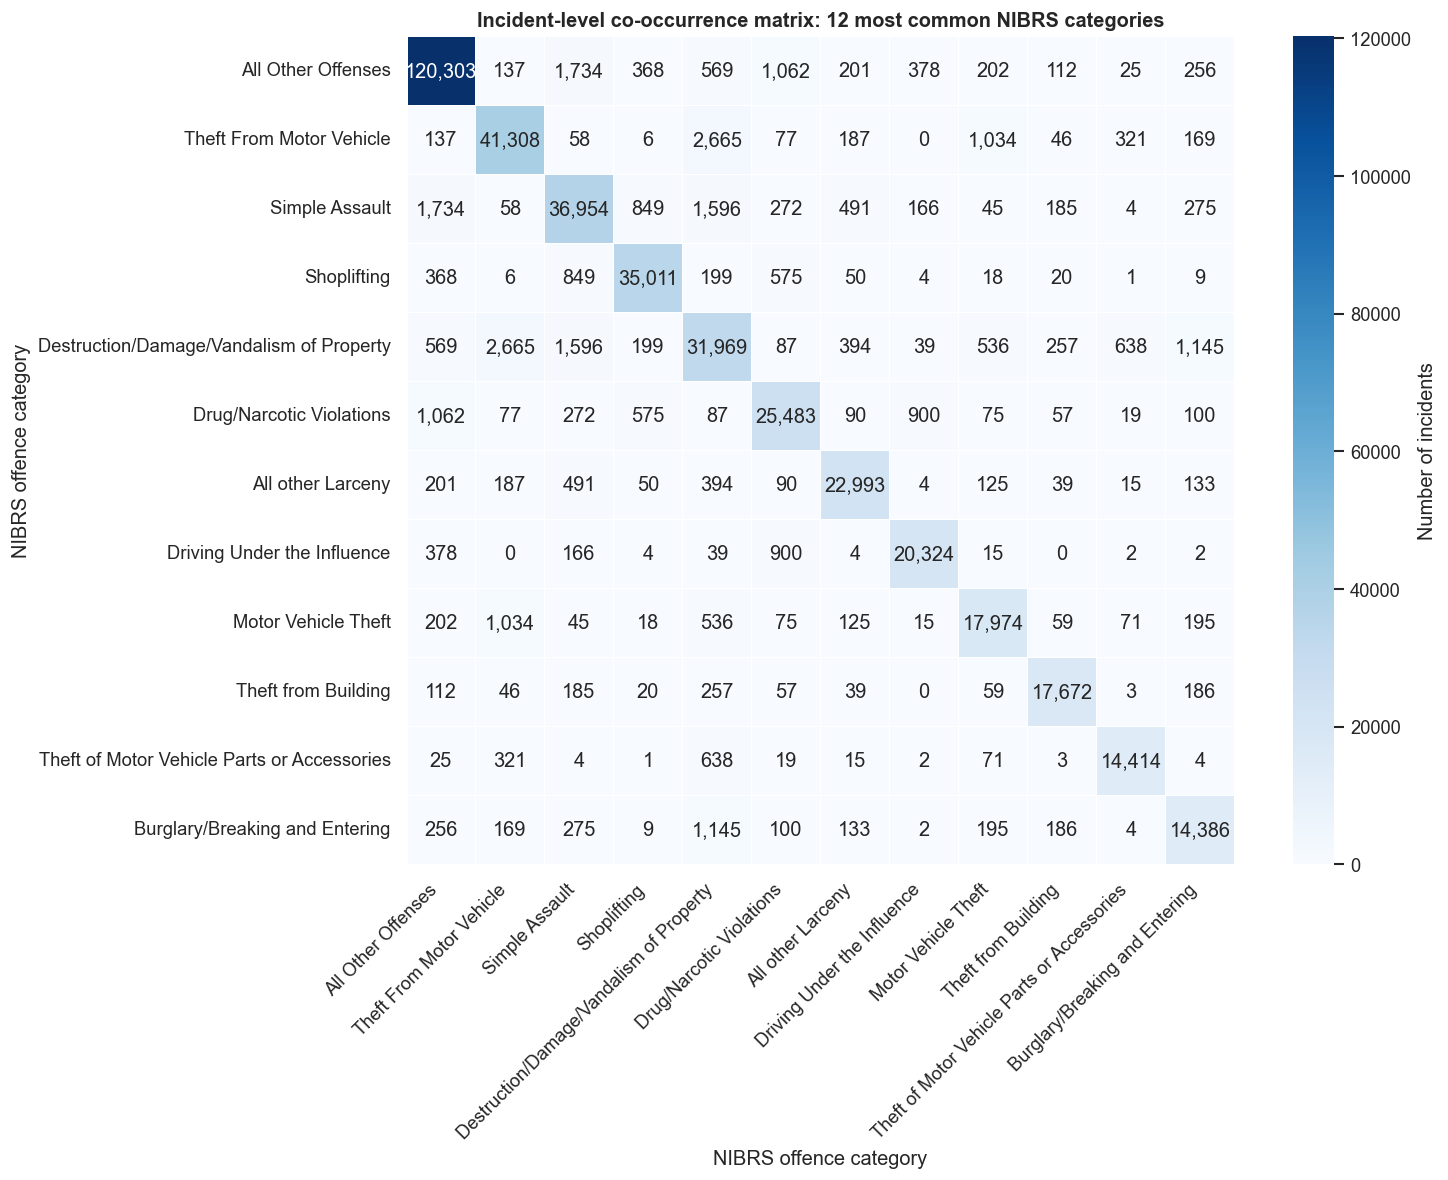

In [15]:
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    co_matrix, cmap="Blues", annot=True, fmt=",d",
    linewidths=0.5, square=True, cbar_kws={"label": "Number of incidents"},
    ax=ax
)
ax.set_title("Incident-level co-occurrence matrix: 12 most common NIBRS categories", weight="bold")
ax.set_xlabel("NIBRS offence category")
ax.set_ylabel("NIBRS offence category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**How to interpret Figure 2:** Compare off-diagonal cells rather than the diagonal when identifying co-occurring pairs. Large counts can partly reflect the overall popularity of each category. For a more rigorous comparison, the next cell calculates lift: observed pair frequency divided by the frequency expected under independence. Lift above 1 indicates more co-occurrence than expected from the marginal frequencies, but rare pairs can have unstable estimates.

In [16]:
n_incidents = len(df)
lift_rows = []
for row in pair_counts.itertuples(index=False):
    count_a = int(category_incident_counts.get(row[0], 0))
    count_b = int(category_incident_counts.get(row[1], 0))
    expected = (count_a * count_b) / n_incidents if n_incidents else np.nan
    lift_rows.append((row[0], row[1], int(row[2]), expected, row[2] / expected if expected else np.nan))

pair_association = pd.DataFrame(
    lift_rows,
    columns=["Category A", "Category B", "Observed incidents", "Expected under independence", "Lift"]
).sort_values(["Lift", "Observed incidents"], ascending=[False, False])
display(pair_association.head(20))

,Category A,Category B,Observed incidents,Expected under independence,Lift
109,Assisting or Promoting Prostitution,"Human Trafficking, Commercial Sex Acts",60,0.030958,1938.108594
97,"Human Trafficking, Commercial Sex Acts",Prostitution,74,0.058097,1273.741957
72,Assisting or Promoting Prostitution,Prostitution,112,0.095179,1176.724756
398,Incest,Statuory Rape,2,0.005475,365.313281
511,"Human Trafficking, Involuntary Servitude",Pornography/Obscene Material,1,0.007879,126.927524
515,Liquor Law Violations,Operating/Promoting/Assisting Gambling,1,0.017141,58.340736
459,Incest,Pornography/Obscene Material,1,0.042019,23.798911
419,Kidnapping/Abduction,Murder and Nonnegligent Manslaughter,1,0.055239,18.103020
518,From Coin/Operated Machine or Device,Stolen Property Offenses,1,0.058794,17.008621
158,Stolen Property Offenses,Weapon Law Violations,29,2.766008,10.484425


## Conclusion and limitations

Use the outputs above to answer the research question with evidence from both visualisations.

- The pair chart identifies the most frequent combinations.
- The heatmap shows the broader co-occurrence structure among common categories.
- Lift provides context beyond raw counts, but should be interpreted alongside the observed count.
- Only founded, reported police records are represented; unreported crime is not observed.
- NIBRS category co-occurrence does not establish temporal order, causality, offender identity, or a common victim.
- `Crime Name2` is a category label, not a unique offence code. Different local descriptions may sit within the same NIBRS category.

**Suggested reporting sentence:** “At incident level, the most frequent co-occurring category pairs were …, while the heatmap showed … . These patterns indicate recurring combinations in the recorded incidents, not causal relationships.”